# MenoPhenotype — Notebook 8: Model Selection & Training

**Course stages covered:** Stage 11 (Model Selection) and Stage 12 (Model Training).
**Input:** `artifacts/baseline_train_features.csv`, `artifacts/feature_sets.json`.
**Output:** `artifacts/model_sweep_results.csv` (every model/hyperparameter combination tried, with its
internal-validity scores) — the raw material Notebook 9 uses to actually *choose* each model's
hyperparameters.

This notebook only **trains across a grid and records metrics** for each of the four algorithm families named
in the project blueprint. It does not yet pick a winner per family or declare a final k — that selection,
plus stability analysis and a proper justified choice, is Notebook 9's job. Everything below is fit on the
**training split only** (`Xtr`), matching Notebook 6's recommendation to cluster on feature Set A (18 symptom
items); hormones/BMI/age are intentionally excluded from clustering and reserved for profiling.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams['figure.dpi'] = 100
RNG = 42
ART = Path('artifacts')
fs = json.load(open(ART / 'feature_sets.json'))
SET_A = fs['sets']['A']
Xtr = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')[SET_A]
print(Xtr.shape)

def score(X, lab):
    mask = lab != -1  # exclude DBSCAN noise points from validity scoring
    if mask.sum() < len(lab):
        X, lab = X[mask], lab[mask]
    if len(set(lab)) < 2:
        return {'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    return {'silhouette': round(float(silhouette_score(X, lab)), 3),
            'davies_bouldin': round(float(davies_bouldin_score(X, lab)), 3),
            'calinski_harabasz': round(float(calinski_harabasz_score(X, lab)), 1)}

results = []


(2632, 18)


## A. Why these four algorithm families (blueprint Section 7)

| Model | Why appropriate here |
|---|---|
| **K-Means** | Fast, simple, standard baseline-beater for spherical clusters; needed as the reference every other model is compared against |
| **Agglomerative (Ward linkage)** | No assumption of spherical clusters; the dendrogram gives a visual, defensible way to justify a chosen k, and doesn't require guessing k up front |
| **DBSCAN** | Density-based — finds arbitrarily shaped clusters *and* explicitly flags outlier/atypical women as noise, matching the blueprint's separate outlier-detection requirement (Section 7) |
| **Gaussian Mixture Model** | *Soft* clustering — gives each woman a probability of belonging to each phenotype, which fits the blueprint's core premise that symptom profiles genuinely overlap rather than falling into hard-edged groups |


## B. K-Means: train k = 2..8

In [2]:
for k in range(2, 9):
    m = KMeans(n_clusters=k, random_state=RNG, n_init=10).fit(Xtr)
    s = score(Xtr, m.labels_)
    results.append({'model': 'KMeans', 'params': f'k={k}', 'k': k, 'inertia': round(m.inertia_, 1), **s})

kmeans_df = pd.DataFrame([r for r in results if r['model'] == 'KMeans'])
kmeans_df


,model,params,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,KMeans,k=2,2,38180.5,0.360,1.813,633.4
1,KMeans,k=3,3,35015.1,0.172,2.268,464.0
2,KMeans,k=4,4,33435.1,0.156,2.278,365.3
3,KMeans,k=5,5,31924.3,0.153,2.402,317.9
4,KMeans,k=6,6,30843.3,0.128,2.312,281.5
5,KMeans,k=7,7,29898.7,0.132,2.235,255.7
6,KMeans,k=8,8,29110.4,0.117,2.183,235.2


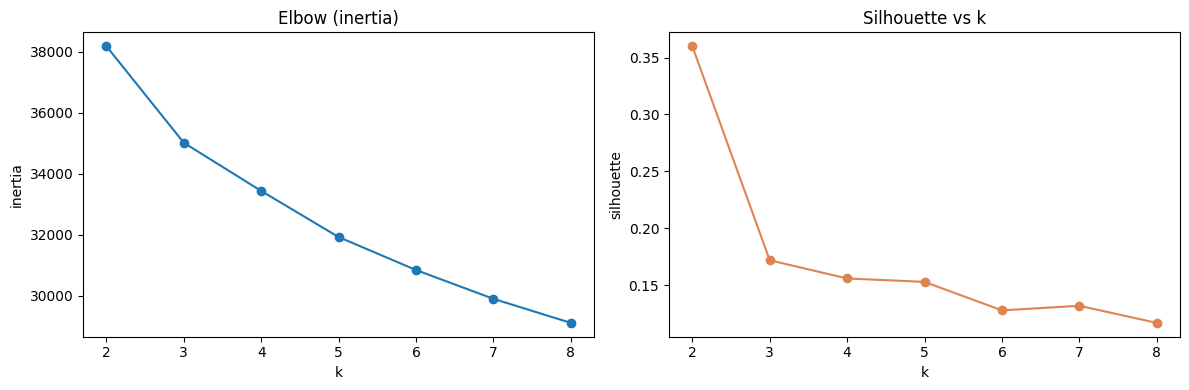

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(kmeans_df['k'], kmeans_df['inertia'], marker='o'); axes[0].set_title('Elbow (inertia)')
axes[0].set_xlabel('k'); axes[0].set_ylabel('inertia')
axes[1].plot(kmeans_df['k'], kmeans_df['silhouette'], marker='o', color='#DD8452')
axes[1].set_title('Silhouette vs k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('silhouette')
plt.tight_layout(); plt.show()


## C. Agglomerative (Ward linkage): dendrogram + k = 2..8

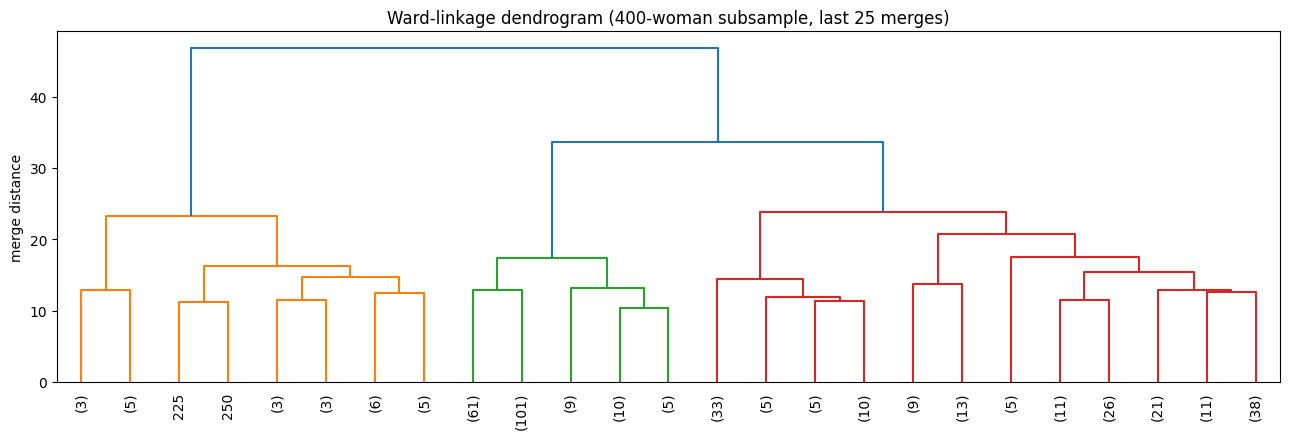

In [4]:
# Dendrogram on a random 400-woman subsample (full 2,632 x 2,632 linkage plot is unreadable)
rs = np.random.RandomState(RNG)
sub_idx = rs.choice(len(Xtr), 400, replace=False)
Z = linkage(Xtr.values[sub_idx], method='ward')
plt.figure(figsize=(13, 4.5))
dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=90)
plt.title('Ward-linkage dendrogram (400-woman subsample, last 25 merges)')
plt.ylabel('merge distance'); plt.tight_layout(); plt.show()


In [5]:
for k in range(2, 9):
    m = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(Xtr)
    s = score(Xtr, m.labels_)
    results.append({'model': 'Agglomerative', 'params': f'k={k}, ward', 'k': k, **s})

agg_df = pd.DataFrame([r for r in results if r['model'] == 'Agglomerative'])
agg_df


,model,params,k,silhouette,davies_bouldin,calinski_harabasz
0,Agglomerative,"k=2, ward",2,0.466,1.546,443.0
1,Agglomerative,"k=3, ward",3,0.067,2.350,342.7
2,Agglomerative,"k=4, ward",4,0.071,2.190,271.5
3,Agglomerative,"k=5, ward",5,0.058,2.948,238.1
4,Agglomerative,"k=6, ward",6,0.064,2.721,212.2
5,Agglomerative,"k=7, ward",7,0.067,2.614,194.6
6,Agglomerative,"k=8, ward",8,0.072,2.455,181.3


## D. DBSCAN: k-distance plot to locate a candidate `eps`, then a small grid

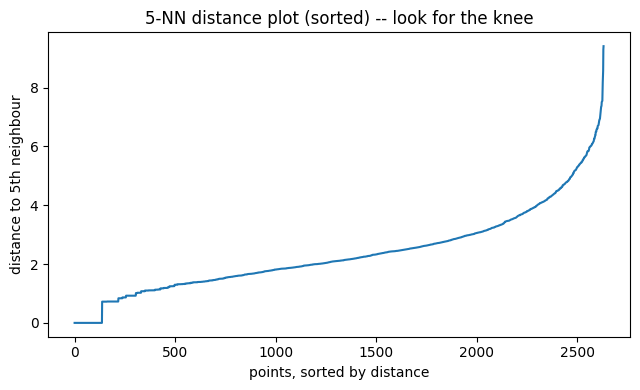

Distance percentiles: {50: 2.11, 75: 3.01, 90: 4.29, 95: 5.29, 99: 6.72}


In [6]:
# k-distance plot: distance to the 5th nearest neighbour, sorted -- the "knee" suggests a workable eps
k_nn = 5
nn = NearestNeighbors(n_neighbors=k_nn).fit(Xtr)
dist, _ = nn.kneighbors(Xtr)
kdist = np.sort(dist[:, -1])
plt.figure(figsize=(6.5, 4))
plt.plot(kdist)
plt.title(f'{k_nn}-NN distance plot (sorted) -- look for the knee')
plt.xlabel('points, sorted by distance'); plt.ylabel(f'distance to {k_nn}th neighbour')
plt.tight_layout(); plt.show()
print("Distance percentiles:", {p: round(float(np.percentile(kdist, p)), 2) for p in [50, 75, 90, 95, 99]})


In [7]:
for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
    for min_samples in [5, 10, 20]:
        m = DBSCAN(eps=eps, min_samples=min_samples).fit(Xtr)
        n_clusters = len(set(m.labels_)) - (1 if -1 in m.labels_ else 0)
        noise_pct = round(100 * (m.labels_ == -1).mean(), 1)
        s = score(Xtr, m.labels_) if n_clusters >= 2 else {'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
        results.append({'model': 'DBSCAN', 'params': f'eps={eps}, min_samples={min_samples}',
                         'k': n_clusters, 'noise_pct': noise_pct, **s})

dbscan_df = pd.DataFrame([r for r in results if r['model'] == 'DBSCAN'])
dbscan_df


,model,params,k,noise_pct,silhouette,davies_bouldin,calinski_harabasz
0,DBSCAN,"eps=1.5, min_samples=5",6,64.8,0.020,1.430,10.9
1,DBSCAN,"eps=1.5, min_samples=10",1,71.1,NaN,NaN,NaN
2,DBSCAN,"eps=1.5, min_samples=20",1,74.8,NaN,NaN,NaN
3,DBSCAN,"eps=2.0, min_samples=5",3,45.5,0.114,1.406,19.4
4,DBSCAN,"eps=2.0, min_samples=10",1,49.2,NaN,NaN,NaN
5,DBSCAN,"eps=2.0, min_samples=20",1,52.0,NaN,NaN,NaN
6,DBSCAN,"eps=2.5, min_samples=5",3,30.2,0.278,0.967,16.3
7,DBSCAN,"eps=2.5, min_samples=10",1,32.9,NaN,NaN,NaN
8,DBSCAN,"eps=2.5, min_samples=20",1,34.7,NaN,NaN,NaN
9,DBSCAN,"eps=3.0, min_samples=5",1,19.5,NaN,NaN,NaN


**Reading the DBSCAN grid:** many combinations collapse to a single cluster (0 informative structure) or leave
most points as noise — this is a well-known DBSCAN behaviour on data with no sharp density gaps, like ordinal
survey scores. It does not mean DBSCAN failed; it means it is doing its job — flagging that this feature space
doesn't have DBSCAN's assumed dense/sparse regions the way spatial data does. Notebook 9 decides whether any
DBSCAN setting is usable for phenotyping, or whether it's kept only for its noise flag as an outlier detector
(the blueprint's Section 7 also names Isolation Forest/LOF for that job specifically).


## E. Gaussian Mixture Model: k = 2..8 × covariance type, scored by BIC/AIC and silhouette

In [8]:
for k in range(2, 9):
    for cov in ['full', 'diag', 'tied', 'spherical']:
        m = GaussianMixture(n_components=k, covariance_type=cov, random_state=RNG, n_init=3).fit(Xtr)
        lab = m.predict(Xtr)
        s = score(Xtr, lab)
        results.append({'model': 'GMM', 'params': f'k={k}, cov={cov}', 'k': k, 'covariance_type': cov,
                         'bic': round(m.bic(Xtr), 1), 'aic': round(m.aic(Xtr), 1), **s})

gmm_df = pd.DataFrame([r for r in results if r['model'] == 'GMM'])
gmm_df.head(12)


,model,params,k,covariance_type,bic,aic,silhouette,davies_bouldin,calinski_harabasz
0,GMM,"k=2, cov=full",2,full,85472.6,83245.8,0.295,2.366,412.4
1,GMM,"k=2, cov=diag",2,diag,90483.4,90054.5,0.309,2.175,487.8
2,GMM,"k=2, cov=tied",2,tied,120482.4,119260.3,0.457,1.581,366.6
3,GMM,"k=2, cov=spherical",2,spherical,115806.0,115576.9,0.245,2.164,501.1
4,GMM,"k=3, cov=full",3,full,65089.2,61746.0,0.104,3.197,291.9
5,GMM,"k=3, cov=diag",3,diag,68532.6,67886.3,0.127,3.097,341.3
6,GMM,"k=3, cov=tied",3,tied,119794.1,118460.3,0.250,2.233,292.1
7,GMM,"k=3, cov=spherical",3,spherical,110624.8,110278.1,0.039,2.430,353.6
8,GMM,"k=4, cov=full",4,full,65547.5,61088.0,0.082,3.253,220.2
9,GMM,"k=4, cov=diag",4,diag,62406.1,61542.4,0.143,2.829,263.9


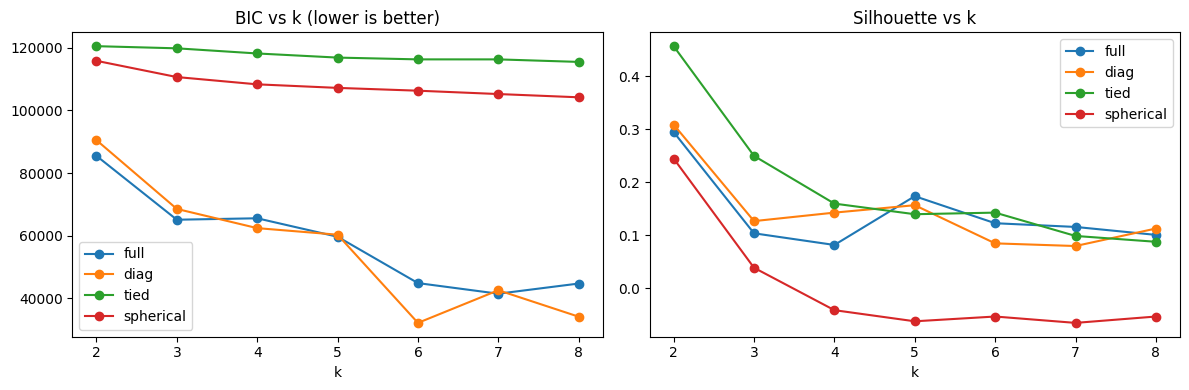

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cov in ['full', 'diag', 'tied', 'spherical']:
    sub = gmm_df[gmm_df['covariance_type'] == cov]
    axes[0].plot(sub['k'], sub['bic'], marker='o', label=cov)
    axes[1].plot(sub['k'], sub['silhouette'], marker='o', label=cov)
axes[0].set_title('BIC vs k (lower is better)'); axes[0].set_xlabel('k'); axes[0].legend()
axes[1].set_title('Silhouette vs k'); axes[1].set_xlabel('k'); axes[1].legend()
plt.tight_layout(); plt.show()


## F. Save the full sweep

In [10]:
sweep = pd.DataFrame(results)
sweep.to_csv(ART / 'model_sweep_results.csv', index=False)
print(sweep.shape, "rows saved to model_sweep_results.csv")
sweep.groupby('model').size()


(60, 11) rows saved to model_sweep_results.csv


model
Agglomerative     7
DBSCAN           18
GMM              28
KMeans            7
dtype: int64

### Summary

| Item | Detail |
|---|---|
| Trained | K-Means (k=2-8), Agglomerative/Ward (k=2-8), DBSCAN (6×3 eps/min_samples grid), GMM (k=2-8 × 4 covariance types) |
| Feature set used | A — 18 symptom items (train split only) |
| Early read | K-Means/Agglomerative elbow and BIC curves both flatten somewhere in the low-to-mid single digits (see plots); DBSCAN struggles to find clean density gaps on ordinal survey data |
| Saved | `model_sweep_results.csv` — every combination tried, with its metrics |
| Next notebook | Notebook 9 — Hyperparameter Tuning (pick each family's best k/params via elbow + silhouette + gap statistic + bootstrap stability, finalize one model per family) |
